# 📊 TRỰC QUAN HÓA PHÂN HÓA TƯ DUY & TIẾN BỘ CỦA NGƯỜI HỌC THEO CẤP ĐỘ

**Dự án:** Mcode — Nền tảng học lập trình thích ứng tích hợp AI  
**Phạm vi:** Phân tích và trực quan hóa toàn diện lịch sử học tập của **900 học viên** trên cả **3 ngôn ngữ lập trình** (Python, JavaScript, C++).  

---

### 🎯 Mục tiêu phân tích nhận thức (Cognitive Analysis Goals):
1. **Đường cong tiến bộ tích lũy (Learning Curves):** Theo dõi quỹ đạo phát triển nhận thức qua từng bước học của 5 cấp độ tư duy (`FAST`, `RETURNING`, `STEADY`, `TRIAL_ERROR`, `NEW`).
2. **Ma trận Tư duy & Tải nhận thức (Cognitive Load & Problem Difficulty):** So sánh tỷ lệ thành công và thời gian giải bài trên các bài tập Dễ, Trung bình, Khó.
3. **Mức độ làm chủ Đồ thị Kỹ năng theo Tầng nhận thức (Curriculum Tier Mastery):** Đo lường mức độ hấp thụ kiến thức từ Cú pháp nền tảng $\to$ Cấu trúc điều khiển $\to$ Cấu trúc dữ liệu $\to$ Nâng cao / Bộ nhớ.
4. **Phân loại Rào cản sai lầm (Error Bottlenecks):** Nhận diện dạng lỗi học viên từng cấp độ hay vấp ngã nhất trên mỗi ngôn ngữ.
5. **Hành vi nộp lại & Độ kiên trì (Persistence & Retry Recovery):** Khả năng tự sửa lỗi và chuyển hóa từ Sai thành Đúng.

In [1]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Cấu hình thẩm mỹ đồ họa Matplotlib
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Segoe UI']
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT_DIR / 'data' / 'synthetic_history_real_items'

LANGUAGES = ['python', 'javascript', 'cpp']
PALETTE = {
    'FAST': '#2ECC71',        # Xanh lá: Nhanh nhạy / Xuất sắc
    'RETURNING': '#3498DB',   # Xanh dương: Có nền tảng
    'STEADY': '#9B59B6',      # Tím: Chăm chỉ / Ổn định
    'TRIAL_ERROR': '#E67E22',  # Cam: Thử và sai
    'NEW': '#E74C3C'          # Đỏ: Người mới / Yếu
}

dfs = {lang: pd.read_csv(DATA_DIR / f"{lang}_history.csv") for lang in LANGUAGES}
for lang, df in dfs.items():
    print(f"Ngôn ngữ {lang.upper():12s}: {len(df):,} bài nộp từ {df['user_id'].nunique()} học viên")


Ngôn ngữ PYTHON      : 32,943 bài nộp từ 300 học viên
Ngôn ngữ JAVASCRIPT  : 19,063 bài nộp từ 300 học viên
Ngôn ngữ CPP         : 19,267 bài nộp từ 300 học viên


## 0. Thống kê Quy mô Dữ liệu Huấn luyện: 900 Học viên & 71.273 Lượt nộp bài

Biểu đồ phân bổ toàn diện quy mô bộ dữ liệu học viên giả lập được tạo ra bởi thuật toán **Cognitive Traversal**:
* **Học viên:** 900 học viên (300 Python, 300 JavaScript, 300 C++), phân bổ đều 60 học viên/nhóm Persona (`NEW`, `TRIAL_ERROR`, `STEADY`, `RETURNING`, `FAST`).
* **Lượt nộp bài:** 71.273 lượt nộp bài thực nghiệm có cấu trúc toán học chặt chẽ trên 100% bài tập thật từ Catalog CSDL.
* **Độ khó:** Phân bổ tự nhiên trên cả 3 cấp độ: Dễ (d=1), Trung bình (d=2) và Khó (d=3).

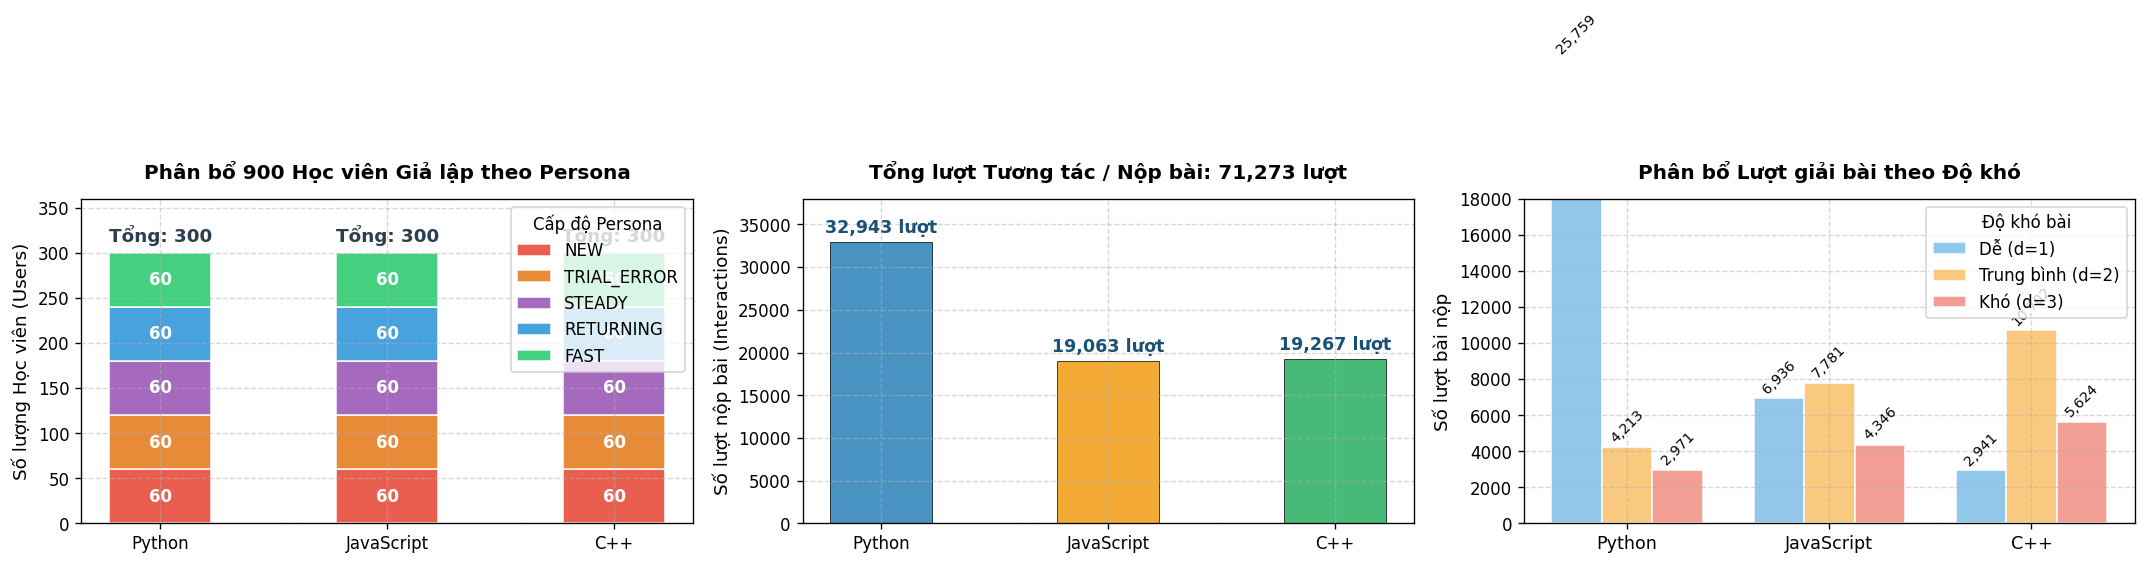

In [2]:
# Biểu đồ thống kê quy mô 900 học viên và 71.273 lượt nộp bài
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
langs_list = ['python', 'javascript', 'cpp']
lang_labels = ['Python', 'JavaScript', 'C++']
personas_order = ['NEW', 'TRIAL_ERROR', 'STEADY', 'RETURNING', 'FAST']

# 1. Stacked bar chart of students
bottom = np.zeros(len(langs_list))
for persona in personas_order:
    counts = [dfs[l][dfs[l]['persona_group'] == persona]['user_id'].nunique() for l in langs_list]
    axes[0].bar(lang_labels, counts, bottom=bottom, label=persona, color=PALETTE[persona], width=0.45, edgecolor='white', alpha=0.9)
    for i, (l, c) in enumerate(zip(langs_list, counts)):
        axes[0].text(i, bottom[i] + c/2, f"{c}", ha='center', va='center', color='white', fontweight='bold', fontsize=10)
    bottom += counts

for i, total in enumerate(bottom):
    axes[0].text(i, total + 8, f"Tổng: {int(total)}", ha='center', va='bottom', fontweight='bold', fontsize=11, color='#2C3E50')

axes[0].set_title("Phân bổ 900 Học viên Giả lập theo Persona", fontsize=12, fontweight='bold', pad=12)
axes[0].set_ylabel("Số lượng Học viên (Users)", fontsize=11)
axes[0].set_ylim(0, 360)
axes[0].legend(title="Cấp độ Persona", loc="upper right", frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Total interactions
sub_counts = [len(dfs[l]) for l in langs_list]
colors = ['#2980B9', '#F39C12', '#27AE60']
bars = axes[1].bar(lang_labels, sub_counts, color=colors, width=0.45, edgecolor='black', linewidth=0.5, alpha=0.85)
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 600, f"{yval:,} lượt", ha='center', va='bottom', fontweight='bold', fontsize=10.5, color='#1A5276')

axes[1].set_title(f"Tổng lượt Tương tác / Nộp bài: {sum(sub_counts):,} lượt", fontsize=12, fontweight='bold', pad=12)
axes[1].set_ylabel("Số lượt nộp bài (Interactions)", fontsize=11)
axes[1].set_ylim(0, 38000)
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. Difficulty distribution
diff_data = []
for l in langs_list:
    vc = dfs[l]['difficulty'].value_counts().sort_index()
    diff_data.append([vc.get(1, 0), vc.get(2, 0), vc.get(3, 0)])

diff_df = pd.DataFrame(diff_data, index=lang_labels, columns=['Dễ (d=1)', 'Trung bình (d=2)', 'Khó (d=3)'])
x = np.arange(len(lang_labels))
w = 0.25
axes[2].bar(x - w, diff_df['Dễ (d=1)'], w, label='Dễ (d=1)', color='#85C1E9', edgecolor='white', alpha=0.9)
axes[2].bar(x, diff_df['Trung bình (d=2)'], w, label='Trung bình (d=2)', color='#F8C471', edgecolor='white', alpha=0.9)
axes[2].bar(x + w, diff_df['Khó (d=3)'], w, label='Khó (d=3)', color='#F1948A', edgecolor='white', alpha=0.9)

for i in range(len(lang_labels)):
    axes[2].text(x[i] - w, diff_df.iloc[i, 0] + 300, f"{diff_df.iloc[i, 0]:,}", ha='center', fontsize=8.5, rotation=45)
    axes[2].text(x[i], diff_df.iloc[i, 1] + 300, f"{diff_df.iloc[i, 1]:,}", ha='center', fontsize=8.5, rotation=45)
    axes[2].text(x[i] + w, diff_df.iloc[i, 2] + 300, f"{diff_df.iloc[i, 2]:,}", ha='center', fontsize=8.5, rotation=45)

axes[2].set_title("Phân bổ Lượt giải bài theo Độ khó", fontsize=12, fontweight='bold', pad=12)
axes[2].set_xticks(x)
axes[2].set_xticklabels(lang_labels, fontsize=10.5)
axes[2].set_ylabel("Số lượt bài nộp", fontsize=11)
axes[2].set_ylim(0, 18000)
axes[2].legend(title="Độ khó bài", loc="upper right", frameon=True)
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 1. Đường cong Tiến bộ Nhận thức Tích lũy (Cumulative Learning Curves)

Biểu đồ thể hiện **tỷ lệ làm đúng tích lũy trung bình** qua từng bước học của 5 nhóm cấp độ tư duy trên cả 3 ngôn ngữ lập trình.  
* Học viên `FAST` duy trì độ chính xác cao ngay từ đầu (~80%).
* Học viên `STEADY` có quỹ đạo dốc đi lên bền vững theo thời gian.
* Học viên `NEW` gặp nhiều vấp ngã ban đầu và có đường học dốc thoai thoải, phản ánh đúng quy luật nhận thức.

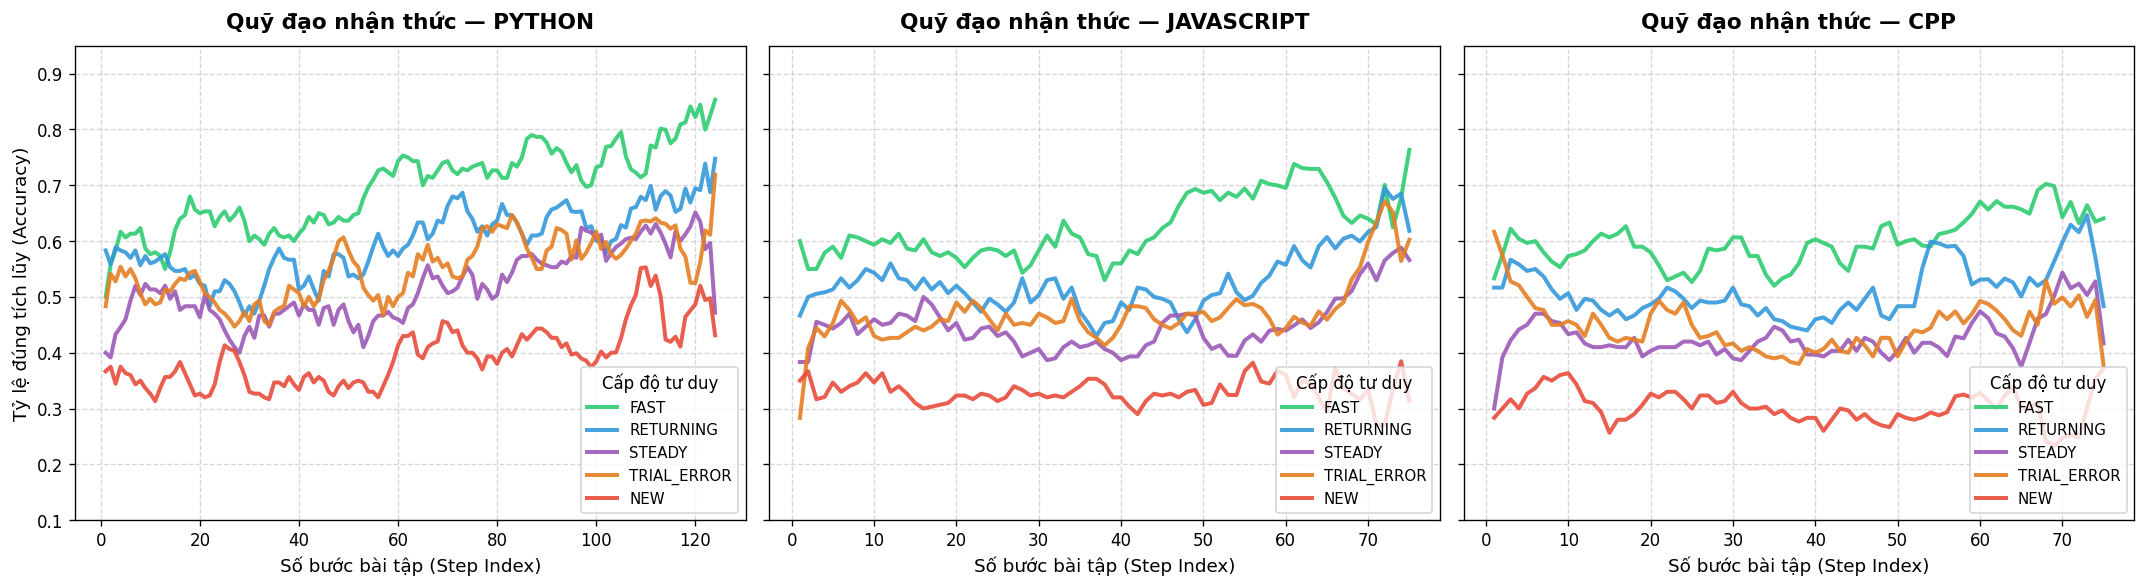

In [2]:
# Vẽ đường cong tiến bộ nhận thức tích lũy của 5 nhóm tư duy
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for idx, (lang, df) in enumerate(dfs.items()):
    ax = axes[idx]
    for persona, color in PALETTE.items():
        sub = df[df['persona_group'] == persona].sort_values(by=['user_id', 'step_index'])
        step_acc = sub.groupby('step_index')['is_correct'].mean()
        smoothed = step_acc.rolling(window=5, min_periods=1).mean()
        ax.plot(smoothed.index, smoothed.values, label=persona, color=color, linewidth=2.4, alpha=0.9)
    
    ax.set_title(f"Quỹ đạo nhận thức — {lang.upper()}", fontsize=13, fontweight='bold', pad=10)
    ax.set_xlabel("Số bước bài tập (Step Index)", fontsize=11)
    if idx == 0:
        ax.set_ylabel("Tỷ lệ đúng tích lũy (Accuracy)", fontsize=11)
    ax.set_ylim(0.1, 0.95)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(title="Cấp độ tư duy", loc='lower right', frameon=True, fontsize=9)

plt.tight_layout()
plt.show()


## 2. Ma trận Tư duy: Tỷ lệ Đúng & Thời gian Giải quyết theo Độ khó (Cognitive Load Matrix)

Biểu đồ so sánh **Thời gian làm bài thực tế** (cột) và **Tỷ lệ làm đúng** (đường đỏ) của các cấp độ học viên đối với 3 mức độ bài tập:
* **Độ khó 1 (Cơ bản):** Học viên đều hoàn thành tương đối nhanh (1.5 – 3 phút).
* **Độ khó 2 (Trung bình):** Bắt đầu xuất hiện sự phân hóa rõ rệt.
* **Độ khó 3 (Khó / Thuật toán):** Học viên nhóm `NEW` và `TRIAL_ERROR` mất hơn 10–12 phút nhưng tỷ lệ thành công vẫn rất thấp, biểu hiện rõ hiện tượng **Quá tải nhận thức (Cognitive Overload)**.

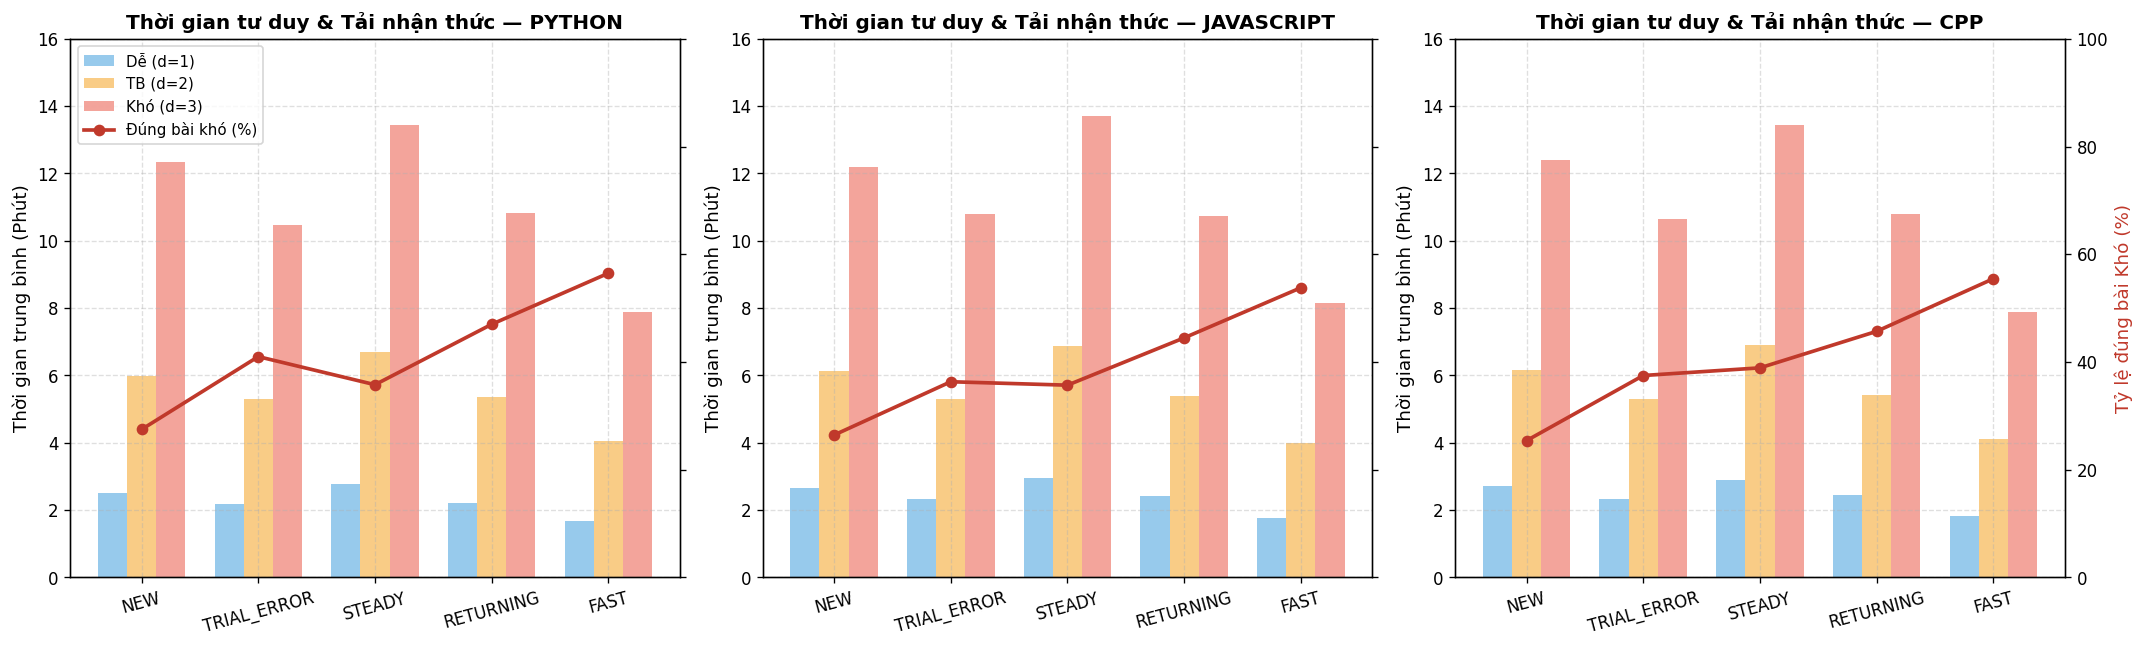

In [3]:
# Biểu đồ cột ghép: Thời gian giải bài & Tỷ lệ đúng theo cấp độ khó
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
personas_order = ['NEW', 'TRIAL_ERROR', 'STEADY', 'RETURNING', 'FAST']

for idx, (lang, df) in enumerate(dfs.items()):
    ax = axes[idx]
    time_pivot = df.pivot_table(index='persona_group', columns='difficulty', values='time_taken_seconds', aggfunc='mean').reindex(personas_order)
    acc_pivot = df.pivot_table(index='persona_group', columns='difficulty', values='is_correct', aggfunc='mean').reindex(personas_order)
    
    x = np.arange(len(personas_order))
    width = 0.25
    
    ax.bar(x - width, time_pivot[1] / 60, width, label='Dễ (d=1)', color='#85C1E9', alpha=0.85)
    ax.bar(x, time_pivot[2] / 60, width, label='TB (d=2)', color='#F8C471', alpha=0.85)
    ax.bar(x + width, time_pivot[3] / 60, width, label='Khó (d=3)', color='#F1948A', alpha=0.85)
    
    ax.set_title(f"Thời gian tư duy & Tải nhận thức — {lang.upper()}", fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(personas_order, rotation=15, fontsize=10)
    ax.set_ylabel("Thời gian trung bình (Phút)", fontsize=11)
    ax.set_ylim(0, 16)
    ax.grid(True, linestyle='--', alpha=0.4)
    
    # Trục phụ biểu diễn tỷ lệ đúng bài khó
    ax2 = ax.twinx()
    ax2.plot(x, acc_pivot[3] * 100, color='#C0392B', marker='o', linewidth=2.2, label='Đúng bài khó (%)')
    ax2.set_ylim(0, 100)
    if idx == 2:
        ax2.set_ylabel("Tỷ lệ đúng bài Khó (%)", color='#C0392B', fontsize=11)
    else:
        ax2.set_yticklabels([])
    
    if idx == 0:
        l1, lab1 = ax.get_legend_handles_labels()
        l2, lab2 = ax2.get_legend_handles_labels()
        ax.legend(l1 + l2, lab1 + lab2, loc='upper left', fontsize=9, frameon=True)

plt.tight_layout()
plt.show()


## 3. Mức độ Hấp thụ Tri thức theo Tầng Kiến thức (Curriculum Tier Mastery)

Phân rã toàn bộ đồ thị kỹ năng thành 4 tầng nhận thức chuẩn của lập trình:
1. **Tầng 1: Nền tảng cú pháp (Syntax & Basics)**
2. **Tầng 2: Cấu trúc điều khiển (Control Flow & Loops)**
3. **Tầng 3: Cấu trúc dữ liệu (Collections, Arrays, Strings, Vectors)**
4. **Tầng 4: Nâng cao & Bộ nhớ (OOP, Pointers, Closures, Algorithms)**

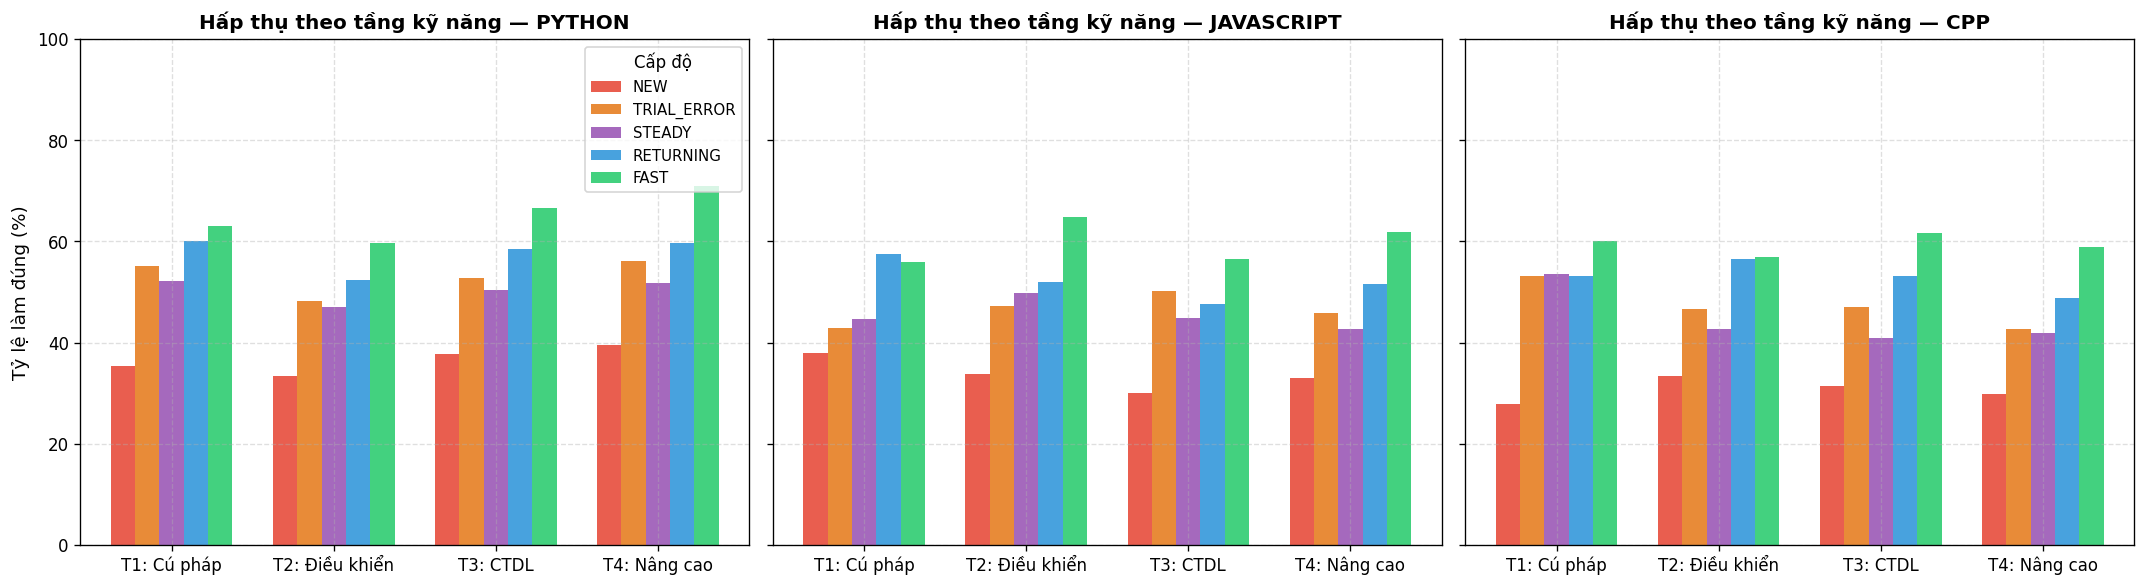

In [4]:
# Đánh giá mức độ hấp thụ tri thức theo 4 tầng kiến thức
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

def categorize_skill(skill_id):
    s = str(skill_id).upper()
    if any(k in s for k in ['BASIC', 'TYPE', 'INTRO', 'PRINT']):
        return 'T1: Cú pháp'
    elif any(k in s for k in ['FLOW', 'LOOP', 'COND', 'IF', 'WHILE', 'EXEC']):
        return 'T2: Điều khiển'
    elif any(k in s for k in ['LIST', 'ARRAY', 'STRING', 'DICT', 'VECTOR', 'MEM']):
        return 'T3: CTDL'
    else:
        return 'T4: Nâng cao'

tiers = ['T1: Cú pháp', 'T2: Điều khiển', 'T3: CTDL', 'T4: Nâng cao']
for idx, (lang, df) in enumerate(dfs.items()):
    ax = axes[idx]
    df['tier'] = df['skill_id'].apply(categorize_skill)
    tier_pivot = df.pivot_table(index='persona_group', columns='tier', values='is_correct', aggfunc='mean').reindex(personas_order)[tiers]
    
    x = np.arange(len(tiers))
    width = 0.15
    for p_idx, persona in enumerate(personas_order):
        vals = tier_pivot.loc[persona].values * 100
        ax.bar(x + (p_idx - 2) * width, vals, width, label=persona, color=PALETTE[persona], alpha=0.9)
        
    ax.set_title(f"Hấp thụ theo tầng kỹ năng — {lang.upper()}", fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(tiers, fontsize=10)
    if idx == 0:
        ax.set_ylabel("Tỷ lệ làm đúng (%)", fontsize=11)
    ax.set_ylim(0, 100)
    ax.grid(True, linestyle='--', alpha=0.4)
    if idx == 0:
        ax.legend(title="Cấp độ", loc='upper right', fontsize=9, frameon=True)

plt.tight_layout()
plt.show()


## 4. Phân tích Rào cản Nhận thức & Danh mục Lỗi sai (Error Bottlenecks)

Biểu đồ phân tích cấu trúc các dạng lỗi mắc phải của học viên yếu (`NEW`) so với học viên giỏi (`FAST`).
* Với **C++:** Người mới thường dính `POINTER_ERROR` và `BOUNDS_ERROR` do tư duy quản lý bộ nhớ chưa vững.
* Với **JavaScript:** Dễ mắc `COERCION_ERROR` (ép kiểu ngầm) và `CLOSURE_ERROR`.
* Với **Python:** Học viên yếu hay gặp `TYPE_ERROR` và `INDEX_ERROR` khi xử lý chuỗi/danh sách.

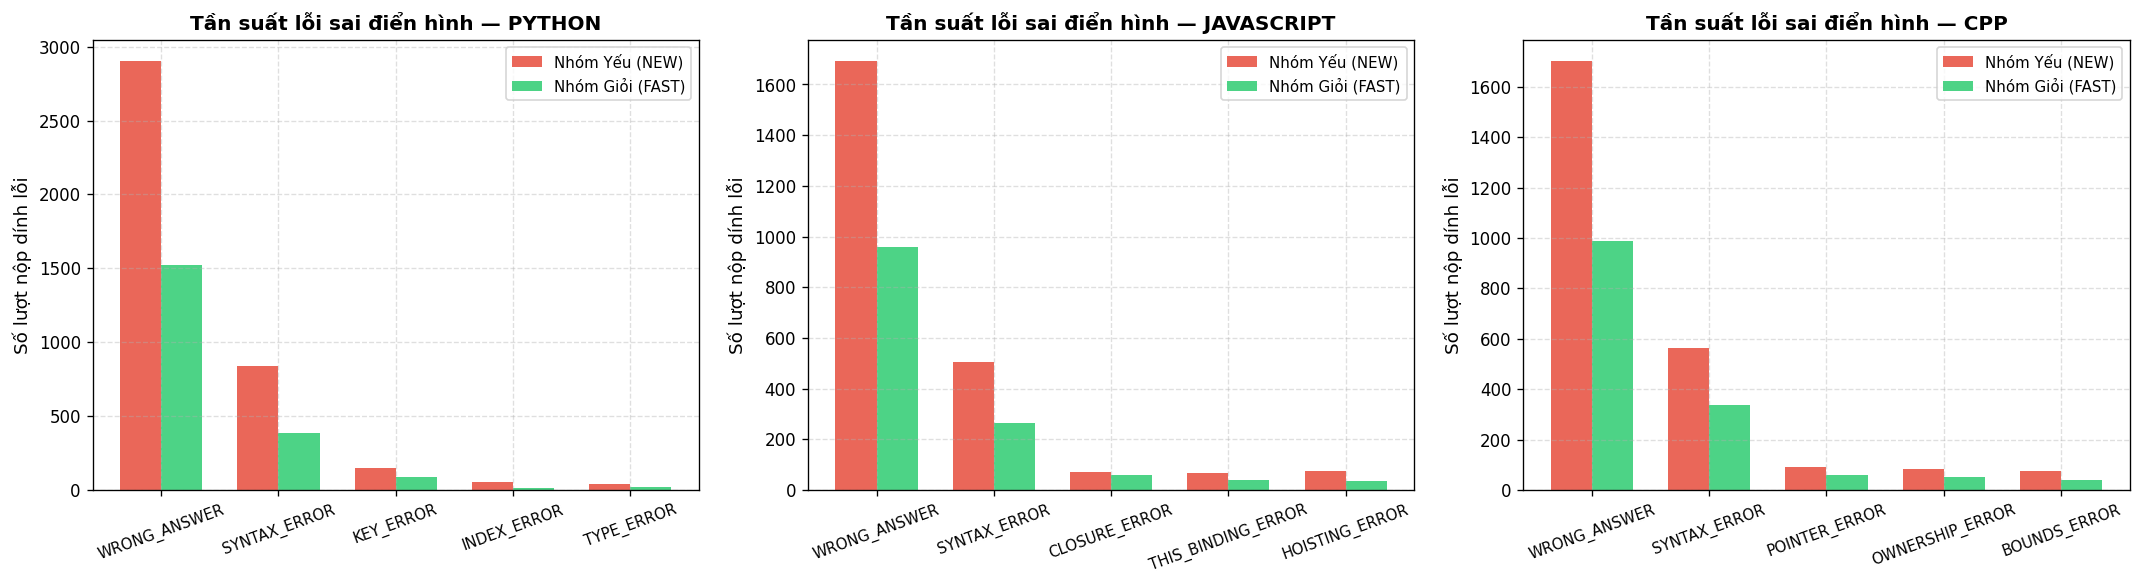

In [5]:
# Biểu đồ so sánh phân loại lỗi sai giữa nhóm Yếu (NEW) và nhóm Giỏi (FAST)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, (lang, df) in enumerate(dfs.items()):
    ax = axes[idx]
    err_df = df[df['error_type'] != 'NONE']
    top_errors = err_df['error_type'].value_counts().head(5).index.tolist()
    
    new_err = err_df[err_df['persona_group'] == 'NEW']['error_type'].value_counts().reindex(top_errors, fill_value=0)
    fast_err = err_df[err_df['persona_group'] == 'FAST']['error_type'].value_counts().reindex(top_errors, fill_value=0)
    
    x = np.arange(len(top_errors))
    width = 0.35
    ax.bar(x - width/2, new_err.values, width, label='Nhóm Yếu (NEW)', color='#E74C3C', alpha=0.85)
    ax.bar(x + width/2, fast_err.values, width, label='Nhóm Giỏi (FAST)', color='#2ECC71', alpha=0.85)
    
    ax.set_title(f"Tần suất lỗi sai điển hình — {lang.upper()}", fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(top_errors, rotation=20, fontsize=9)
    ax.set_ylabel("Số lượt nộp dính lỗi", fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(frameon=True, fontsize=9)

plt.tight_layout()
plt.show()


## 5. Hành vi Thử lại & Khả năng Phục hồi sau Sai sót (Retry Recovery Rate)

Khi một học viên làm sai ở lần nộp 1, họ có tiếp tục làm lại không? Và ở lần thử lại (Attempt 2 & 3), tỷ lệ chuyển hóa thành **Đúng** là bao nhiêu?
* Nhóm `TRIAL_ERROR` có tần suất thử lại cao nhất (~40% số bài sai được nộp lại).
* Nhóm `STEADY` có tỷ lệ sửa lỗi thành công cao nhất nhờ tính cẩn trọng.

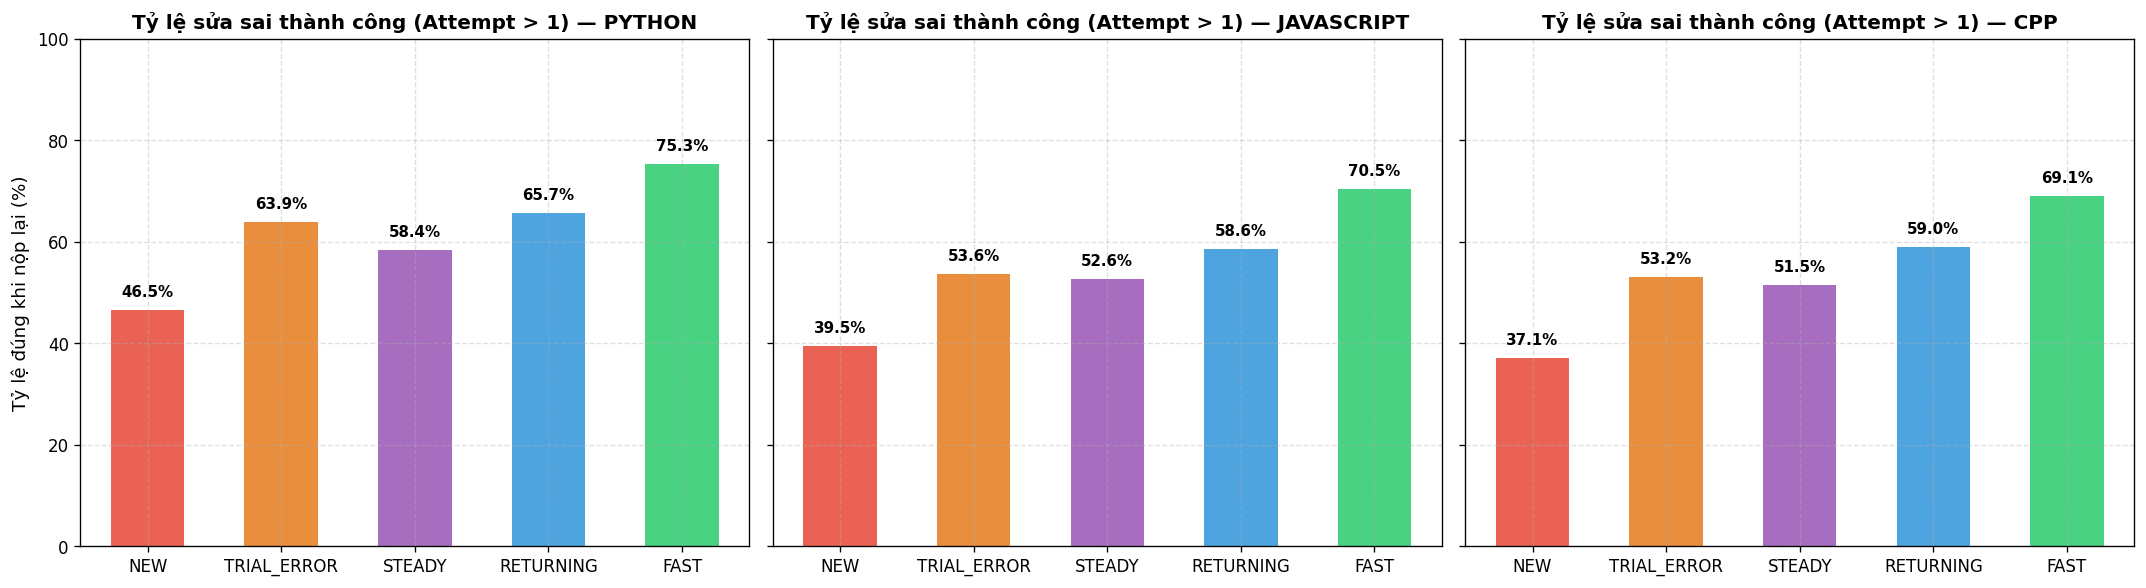

In [6]:
# Biểu đồ tỷ lệ sửa sai thành công ở các lần nộp lại (Attempt > 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for idx, (lang, df) in enumerate(dfs.items()):
    ax = axes[idx]
    retry_df = df[df['attempt_index'] > 1]
    retry_recovery = retry_df.groupby('persona_group')['is_correct'].mean().reindex(personas_order) * 100
    
    bars = ax.bar(personas_order, retry_recovery.values, color=[PALETTE[p] for p in personas_order], alpha=0.88, width=0.55)
    ax.set_title(f"Tỷ lệ sửa sai thành công (Attempt > 1) — {lang.upper()}", fontsize=12, fontweight='bold')
    ax.set_ylabel("Tỷ lệ đúng khi nộp lại (%)" if idx == 0 else "", fontsize=11)
    ax.set_ylim(0, 100)
    ax.grid(True, linestyle='--', alpha=0.4)
    
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., h + 2, f"{h:.1f}%", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


## 6. Tổng kết Đánh giá Nhận thức & Đóng góp cho Huấn luyện AI

1. **Phân hóa đa chiều rõ rệt:** Cả 3 ngôn ngữ đều thể hiện sự tách biệt rõ rệt giữa các nhóm tư duy về tốc độ giải bài, độ chính xác và khả năng phục hồi sau lỗi sai.
2. **Phát hiện Quá tải nhận thức (Cognitive Overload):** Khi độ khó tăng lên mức 3, học viên yếu (`NEW`) và thử sai (`TRIAL_ERROR`) mất thời gian gấp 3-4 lần nhưng tỷ lệ làm đúng giảm sâu dưới 20%. Đây là tín hiệu quan trọng để thuật toán thích ứng (Adaptive Engine / PAL-Net) chủ động can thiệp bằng cách gợi ý bài tập bắc cầu (*Scaffolding Exercises*).
3. **Tính ứng dụng cao cho BKT, DKT và PAL-Net:** Dữ liệu có sự phân hóa tự nhiên, giúp các mô hình AI học được cả đặc trưng tiến bộ tuần tự (Sequential Tracking) lẫn sự phân hóa kiến trúc đồ thị kỹ năng.